# PyTorch Neural Network Classification

| Problem type | What is it? | Example |
| ----- | ----- | ----- |
| **Binary classification** | Target can be one of two options, e.g. yes or no | Predict whether or not someone has heart disease based on their health parameters. |
| **Multi-class classification** | Target can be one of more than two options | Decide whether a photo is of food, a person or a dog. |
| **Multi-label classification** | Target can be assigned more than one option | Predict what categories should be assigned to a Wikipedia article (e.g. mathematics, science & philosophy). |

<div align="center">
<img src="https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/02-different-classification-problems.png" alt="various different classification in machine learning such as binary classification, multiclass classification and multilabel classification" width=900/>
</div>

In other words, taking a set of inputs and predicting what class those set of inputs belong to.

Topics to be covered:
| **Topic** | **Contents** |
| ----- | ----- |
| **0. Architecture of a classification neural network** | Neural networks can come in almost any shape or size, but they typically follow a similar floor plan. |
| **1. Getting binary classification data ready** | Data can be almost anything but to get started we're going to create a simple binary classification dataset. |
| **2. Building a PyTorch classification model** | Here we'll create a model to learn patterns in the data, we'll also choose a **loss function**, **optimizer** and build a **training loop** specific to classification. | 
| **3. Fitting the model to data (training)** | We've got data and a model, now let's let the model (try to) find patterns in the (**training**) data. |
| **4. Making predictions and evaluating a model (inference)** | Our model's found patterns in the data, let's compare its findings to the actual (**testing**) data. |
| **5. Improving a model (from a model perspective)** | We've trained and evaluated a model but it's not working, let's try a few things to improve it. |
| **6. Non-linearity** | So far our model has only had the ability to model straight lines, what about non-linear (non-straight) lines? |
| **7. Replicating non-linear functions** | We used **non-linear functions** to help model non-linear data, but what do these look like? |
| **8. Putting it all together with multi-class classification** | Let's put everything we've done so far for binary classification together with a multi-class classification problem. |

### Make classificaion data and get it ready

In [1]:
from sklearn.datasets import make_circles

#make 1000samples
n_samples=1000

X,y=make_circles(n_samples,noise=0.03,random_state=42)

In [2]:
X[:5],y[:5],X.shape,y.shape

(array([[ 0.75424625,  0.23148074],
        [-0.75615888,  0.15325888],
        [-0.81539193,  0.17328203],
        [-0.39373073,  0.69288277],
        [ 0.44220765, -0.89672343]]),
 array([1, 1, 1, 1, 0]),
 (1000, 2),
 (1000,))

There are two X values per one y value.

In [3]:
import pandas as pd
circles=pd.DataFrame({"X1":X[:,0],"X2":X[:,1],"label":y})
circles.head(10)

,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


In [4]:
circles.label.value_counts()

label
1    500
0    500
Name: count, dtype: int64

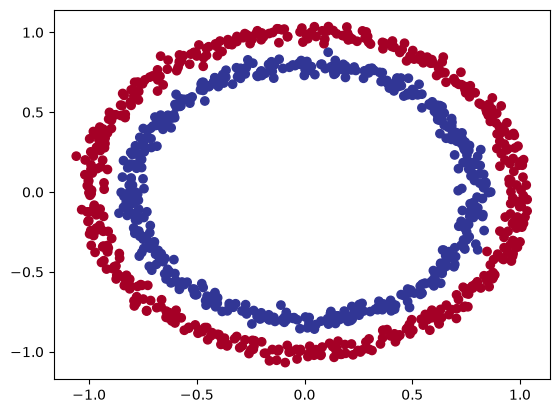

In [5]:
#visualize w a plot
import matplotlib.pyplot as plt
plt.scatter(x=X[:,0],y=X[:,1],c=y,cmap=plt.cm.RdYlBu)

#### Input and Output shapes
One of the most common errors in deep learning is shape errors.

Mismatching the shapes of tensors and tensor operations will result in errors in your models.

In [6]:
X.shape,y.shape

((1000, 2), (1000,))

In [7]:
X_sample=X[0]
y_sample=y[0]
X_sample,X_sample.shape,y_sample,y_sample.shape

(array([0.75424625, 0.23148074]), (2,), np.int64(1), ())

#### Turn data into tensors and create train and test splits
Specifically, we'll need to:
1. Turn our data into tensors (right now our data is in NumPy arrays and PyTorch prefers to work with PyTorch tensors).
2. Split our data into training and test sets (we'll train a model on the training set to learn the patterns between `X` and `y` and then evaluate those learned patterns on the test dataset).

In [8]:
#turn data into tensors
import torch
X=torch.from_numpy(X).type(torch.float)
y=torch.from_numpy(y).type(torch.float)

X[:5],y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [9]:
#split data into train test sets
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42) 
len(X_train),len(X_test),len(y_train),len(y_test)

(800, 200, 800, 200)

### Building our model

In [10]:
import torch
from torch import nn

device="cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [11]:
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1=nn.Linear(in_features=2,out_features=5)
        self.layer_2=nn.Linear(in_features=5,out_features=1)

    def forward(self,x):
        return self.layer_2(self.layer_1(x))

model_0=CircleModelV0().to(device)
model_0

CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

In [12]:
#replicating w Sequential
model_0=nn.Sequential(
    nn.Linear(in_features=2,out_features=5),
    nn.Linear(in_features=5,out_features=1)
).to(device)
model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

nn.Sequential is fantastic for straight-forward computations, however, as the namespace says, it always runs in sequential order.

So if you'd like something else to happen (rather than just straight-forward sequential computation) you'll want to define your own custom nn.Module subclass.

In [13]:
#make prediction
untrained_preds=model_0(X_test.to(device))
len(untrained_preds),len(y_test),y_test.shape,untrained_preds.shape,untrained_preds[:10],y_test[:10]

(200,
 200,
 torch.Size([200]),
 torch.Size([200, 1]),
 tensor([[0.6415],
         [0.7071],
         [0.5127],
         [0.6778],
         [0.5813],
         [0.6208],
         [0.7512],
         [0.7312],
         [0.5100],
         [0.7122]], grad_fn=<SliceBackward0>),
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.]))

### Setup Loss Function and Optimizer

Loss fn- For binary classification, use Binary Cross Entropy <br>
Optimizer-SGD

| Loss function/Optimizer | Problem type | PyTorch Code |
| ----- | ----- | ----- |
| Stochastic Gradient Descent (SGD) optimizer | Classification, regression, many others. | [`torch.optim.SGD()`](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html) |
| Adam Optimizer | Classification, regression, many others. | [`torch.optim.Adam()`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html) |
| Binary cross entropy loss | Binary classification | [`torch.nn.BCELossWithLogits`](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html) or [`torch.nn.BCELoss`](https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html) |
| Cross entropy loss | Multi-class classification | [`torch.nn.CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) |
| Mean absolute error (MAE) or L1 Loss | Regression | [`torch.nn.L1Loss`](https://pytorch.org/docs/stable/generated/torch.nn.L1Loss.html) | 
| Mean squared error (MSE) or L2 Loss | Regression | [`torch.nn.MSELoss`](https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html#torch.nn.MSELoss) |  


PyTorch has two binary cross entropy implementations:
1. [`torch.nn.BCELoss()`](https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html) - Creates a loss function that measures the binary cross entropy between the target (label) and input (features).
2. [`torch.nn.BCEWithLogitsLoss()`](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html) - This is the same as above except it has a sigmoid layer ([`nn.Sigmoid`](https://pytorch.org/docs/stable/generated/torch.nn.Sigmoid.html)) built-in (we'll see what this means soon).

In [14]:
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.01)

In [15]:
#calculate accuracy
def accuracy_fn(y_true,y_pred):
    correct=torch.eq(y_true,y_pred).sum().item()
    acc=(correct/len(y_pred))*100
    return acc

### Train Model

##### Going from raw model outputs to predicted labels (logits -> prediction probabilities -> prediction labels)

Before the training loop steps, let's see what comes out of our model during the forward pass (the forward pass is defined by the `forward()` method).

In [16]:
y_logits=model_0(X_test.to(device))[:5]
y_logits

tensor([[0.6415],
        [0.7071],
        [0.5127],
        [0.6778],
        [0.5813]], grad_fn=<SliceBackward0>)

They're the output of our `forward()` method.

Which implements two layers of `nn.Linear()` which internally calls the following equation:

$$
\mathbf{y} = x \cdot \mathbf{Weights}^T  + \mathbf{bias}
$$

The *raw outputs* (unmodified) of this equation ($y$) and in turn, the raw outputs of our model are often referred to as [**logits**](https://datascience.stackexchange.com/a/31045).

To get our model's raw outputs (logits) into such a form, we can use the [sigmoid activation function](https://pytorch.org/docs/stable/generated/torch.sigmoid.html).

In [17]:
y_pred_probs=torch.sigmoid(y_logits)
y_pred_probs

tensor([[0.6551],
        [0.6698],
        [0.6254],
        [0.6632],
        [0.6414]], grad_fn=<SigmoidBackward0>)

More specificially:

If y_pred_probs >= 0.5, y=1 (class 1) <br>
If y_pred_probs < 0.5, y=0 (class 0)

In [18]:
#fine the predicted labels for above
y_preds=torch.round(y_pred_probs)
y_pred_labels=torch.round(torch.sigmoid(model_0(X_test.to(device))[:5]))
print(torch.eq(y_preds.squeeze(),y_pred_labels.squeeze()))
y_preds.squeeze()

tensor([True, True, True, True, True])


tensor([1., 1., 1., 1., 1.], grad_fn=<SqueezeBackward0>)

#### Building a training and testing loop

In [19]:
torch.manual_seed(42)
epochs=100

X_train,y_train=X_train.to(device),y_train.to(device)
X_test,y_test=X_test.to(device),y_test.to(device)

for epoch in range(epochs):
    model_0.train()
    y_logits=model_0(X_train).squeeze()
    y_pred=torch.round(torch.sigmoid(y_logits))
    loss=loss_fn(y_logits,y_train)
    acc=accuracy_fn(y_true=y_train,y_pred=y_pred)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model_0.eval()
    with torch.inference_mode():
        test_logits=model_0(X_test).squeeze()
        test_pred=torch.round(torch.sigmoid(test_logits))
        test_loss=loss_fn(y_test,test_logits)
        test_acc=accuracy_fn(y_true=y_test,y_pred=test_pred)
    if epoch%10==0:
        print(f"Epoch:{epoch} | Loss:{loss:.5f}, Accuracy:{acc:.2f}% | Test Loss: {test_loss:.5f}, Test Accuracy: {test_acc:.2f}%")

Epoch:0 | Loss:0.73926, Accuracy:50.00% | Test Loss: 0.69823, Test Accuracy: 50.00%
Epoch:10 | Loss:0.73424, Accuracy:50.00% | Test Loss: 0.71542, Test Accuracy: 50.00%
Epoch:20 | Loss:0.72977, Accuracy:50.00% | Test Loss: 0.73160, Test Accuracy: 50.00%
Epoch:30 | Loss:0.72579, Accuracy:50.00% | Test Loss: 0.74683, Test Accuracy: 50.00%
Epoch:40 | Loss:0.72225, Accuracy:50.00% | Test Loss: 0.76117, Test Accuracy: 50.00%
Epoch:50 | Loss:0.71909, Accuracy:50.00% | Test Loss: 0.77469, Test Accuracy: 50.00%
Epoch:60 | Loss:0.71627, Accuracy:50.00% | Test Loss: 0.78742, Test Accuracy: 50.00%
Epoch:70 | Loss:0.71376, Accuracy:50.00% | Test Loss: 0.79942, Test Accuracy: 50.00%
Epoch:80 | Loss:0.71153, Accuracy:50.00% | Test Loss: 0.81074, Test Accuracy: 50.00%
Epoch:90 | Loss:0.70954, Accuracy:50.00% | Test Loss: 0.82142, Test Accuracy: 50.00%


In [20]:
import requests
from pathlib import Path 

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

helper_functions.py already exists, skipping download


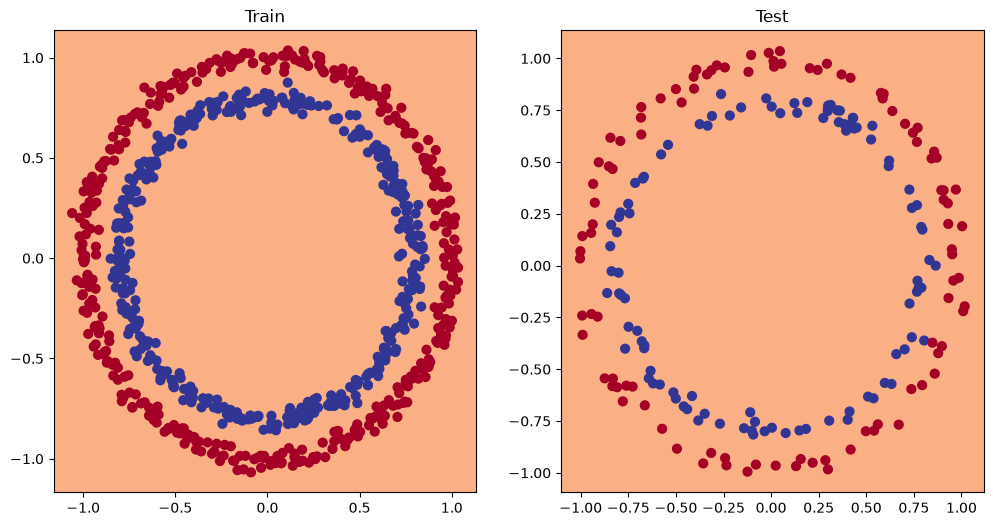

In [21]:
#plot decision boundaries for training and test sets
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_0,X_train,y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_0,X_test,y_test)

| Model improvement technique* | What does it do? |
| ----- | ----- |
| **Add more layers** | Each layer *potentially* increases the learning capabilities of the model with each layer being able to learn some kind of new pattern in the data. More layers are often referred to as making your neural network *deeper*. |
| **Add more hidden units** | Similar to the above, more hidden units per layer means a *potential* increase in learning capabilities of the model. More hidden units are often referred to as making your neural network *wider*. |
| **Fitting for longer (more epochs)** | Your model might learn more if it had more opportunities to look at the data. |
| **Changing the activation functions** | Some data just can't be fit with only straight lines (like what we've seen), using non-linear activation functions can help with this (hint, hint). |
| **Change the learning rate** | Less model specific, but still related, the learning rate of the optimizer decides how much a model should change its parameters each step, too much and the model overcorrects, too little and it doesn't learn enough. |
| **Change the loss function** | Again, less model specific but still important, different problems require different loss functions. For example, a binary cross entropy loss function won't work with a multi-class classification problem. |
| **Use transfer learning** | Take a pretrained model from a problem domain similar to yours and adjust it to your own problem. We cover transfer learning in [notebook 06](https://www.learnpytorch.io/06_pytorch_transfer_learning/). |

> **Note:** *because you can adjust all of these by hand, they're referred to as **hyperparameters**. 

In [22]:
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1=nn.Linear(in_features=2,out_features=10)
        self.layer_2=nn.Linear(in_features=10,out_features=10)
        self.layer_3=nn.Linear(in_features=10,out_features=1)
    def forward(self,x):
        #z=self.layer_1(x)
        #z=self.layer_2(z)
        #z=self.layer_3(z)
        #return z
        return self.layer_3(self.layer_2(self.layer_1(x)))

model_1=CircleModelV1().to(device)
model_1

CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [23]:
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.SGD(params=model_1.parameters(),lr=0.01)


In [24]:
def accuracy_fn(y_true,y_pred):
    correct=torch.eq(y_true,y_pred).sum().item()
    accuracy=(correct/len(y_pred))*100
    return accuracy
    

In [25]:
import torch
torch.manual_seed(42)
epochs=1000

X_train,y_train=X_train.to(device),y_train.to(device)
X_test,y_test=X_test.to(device),y_test.to(device)

for epoch in range(epochs):
    y_logits=model_1(X_train).squeeze()
    y_pred=torch.round(torch.sigmoid(y_logits))

    loss=loss_fn(y_logits,y_train)
    acc=accuracy_fn(y_true=y_train,y_pred=y_pred)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model_1.eval()

    with torch.inference_mode():
        test_logits=model_1(X_test).squeeze()
        test_pred=torch.round(torch.sigmoid(test_logits))
        test_loss=loss_fn(test_logits,y_test)
        test_acc=accuracy_fn(y_true=y_test,y_pred=test_pred)

    if epoch%100==0:
        print(f"Epoch : {epoch} | Loss: {loss:.5f} | Accuracy: {acc:.2f}% | Test Loss:{test_loss:.5f} | Test Accuracy : {test_acc:.2f}%")

Epoch : 0 | Loss: 0.69396 | Accuracy: 50.88% | Test Loss:0.69261 | Test Accuracy : 51.00%
Epoch : 100 | Loss: 0.69369 | Accuracy: 50.25% | Test Loss:0.69269 | Test Accuracy : 50.00%
Epoch : 200 | Loss: 0.69351 | Accuracy: 50.12% | Test Loss:0.69282 | Test Accuracy : 49.50%
Epoch : 300 | Loss: 0.69339 | Accuracy: 50.50% | Test Loss:0.69295 | Test Accuracy : 49.00%
Epoch : 400 | Loss: 0.69329 | Accuracy: 50.38% | Test Loss:0.69309 | Test Accuracy : 48.50%
Epoch : 500 | Loss: 0.69322 | Accuracy: 49.88% | Test Loss:0.69322 | Test Accuracy : 49.50%
Epoch : 600 | Loss: 0.69317 | Accuracy: 49.50% | Test Loss:0.69335 | Test Accuracy : 53.00%
Epoch : 700 | Loss: 0.69313 | Accuracy: 49.38% | Test Loss:0.69347 | Test Accuracy : 50.50%
Epoch : 800 | Loss: 0.69309 | Accuracy: 50.00% | Test Loss:0.69358 | Test Accuracy : 51.00%
Epoch : 900 | Loss: 0.69307 | Accuracy: 50.62% | Test Loss:0.69368 | Test Accuracy : 47.50%


Still doesn't look good. Let's plot it.

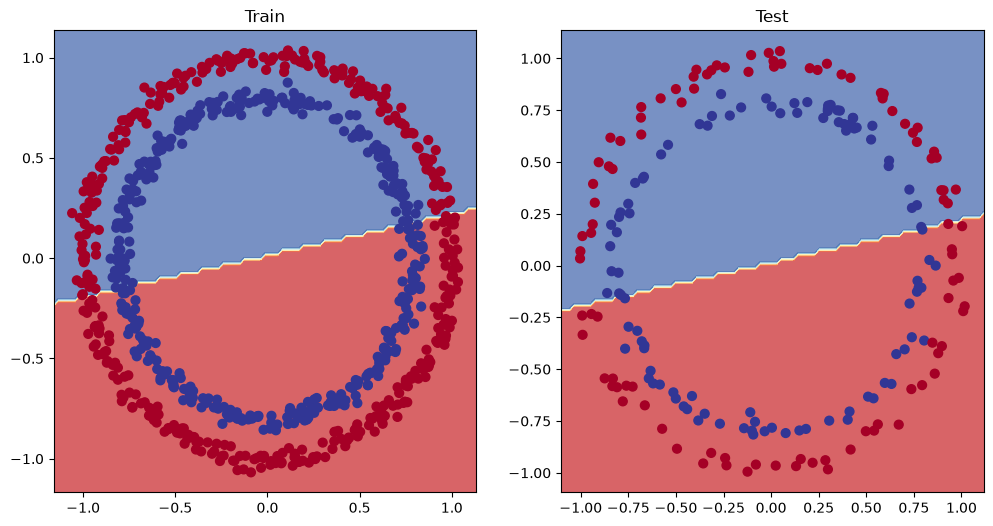

In [26]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_1,X_train,y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_1,X_test,y_test)

#### The missing piece: Non Linearity.

We've seen our model can draw straight (linear) lines, thanks to its linear layers.

But how about we give it the capacity to draw non-straight (non-linear) lines?

By introducing ReLU() activation layer

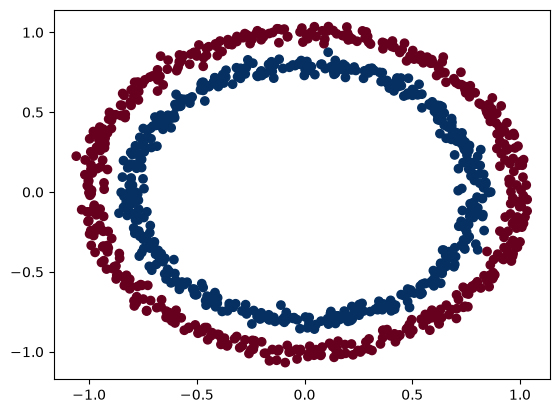

In [27]:
# Recreating Non-Linear data

import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

n_samples=1000
X,y=make_circles(n_samples=1000,noise=0.03,random_state=42)

plt.scatter(X[:,0],X[:,1],c=y,cmap=plt.cm.RdBu);

In [28]:
import torch
from sklearn.model_selection import train_test_split

X=torch.from_numpy(X).type(torch.float)
y=torch.from_numpy(y).type(torch.float)

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
len(X_train),len(y_test)

(800, 200)

In [29]:
from torch import nn
class CircleModeV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1=nn.Linear(in_features=2,out_features=10)
        self.layer_2=nn.Linear(in_features=10,out_features=10)
        self.layer_3=nn.Linear(in_features=10,out_features=1)
        self.relu=nn.ReLU()

    def forward(self,x):
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

model_3=CircleModeV2().to(device)
print(model_3,model_3.state_dict())

CircleModeV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
) OrderedDict([('layer_1.weight', tensor([[ 0.5406,  0.5869],
        [-0.1657,  0.6496],
        [-0.1549,  0.1427],
        [-0.3443,  0.4153],
        [ 0.6233, -0.5188],
        [ 0.6146,  0.1323],
        [ 0.5224,  0.0958],
        [ 0.3410, -0.0998],
        [ 0.5451,  0.1045],
        [-0.3301,  0.1802]])), ('layer_1.bias', tensor([-0.3258, -0.0829, -0.2872,  0.4691, -0.5582, -0.3260, -0.1997, -0.4252,
         0.0667, -0.6984])), ('layer_2.weight', tensor([[ 0.2856, -0.2686,  0.2441,  0.0526, -0.1027,  0.1954,  0.0493,  0.2555,
          0.0346, -0.0997],
        [ 0.0850, -0.0858,  0.1331,  0.2823,  0.1828, -0.1382,  0.1825,  0.0566,
          0.1606, -0.1927],
        [-0.3130, -0.1222, -0.2426,  0.2595,  0.0911,  0.1310,  0.1000, -0.0055,
          0.2475, 

In [30]:
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.SGD(params=model_3.parameters(),lr=0.1)

In [31]:
# # def accuracy_fn(y_true,y_pred):
# #     correct=torch.eq(y_true,y_pred).sum().item()
# #     accuracy=(correct/len(y_pred))*100
# #     return accuracy

# #calculate accuracy
# def accuracy_fn(y_true,y_pred):
#     correct=torch.eq(y_true,y_pred).sum().item()
#     acc=(correct/len(y_pred))*100
#     return acc

In [32]:
torch.manual_seed(42)

epochs=10000

X_train,y_train=X_train.to(device),y_train.to(device)
X_test,y_test=X_test.to(device),y_test.to(device)

for epoch in range(epochs):
    y_logits=model_3(X_train).squeeze()
    y_pred=torch.round(torch.sigmoid(y_logits))

    loss=loss_fn(y_logits,y_train)
    acc=accuracy_fn(y_true=y_train,y_pred=y_pred)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model_3.eval()
    with torch.inference_mode():
        test_logits=model_3(X_test).squeeze()
        test_pred=torch.round(torch.sigmoid(test_logits))
        test_loss=loss_fn(test_logits,y_test)
        test_acc=accuracy_fn(y_true=y_test,y_pred=test_pred)
    if epoch%100==0:
        print(f"Epoch : {epoch} | Loss:{loss:.5f} , Accuracy: {acc:.2f}%100 | Test Loss:{test_loss:.5f}, Test Accuracy:{test_acc:2f}%")

Epoch : 0 | Loss:0.69295 , Accuracy: 50.00%100 | Test Loss:0.69319, Test Accuracy:50.000000%
Epoch : 100 | Loss:0.69115 , Accuracy: 52.88%100 | Test Loss:0.69102, Test Accuracy:52.500000%
Epoch : 200 | Loss:0.68977 , Accuracy: 53.37%100 | Test Loss:0.68940, Test Accuracy:55.000000%
Epoch : 300 | Loss:0.68795 , Accuracy: 53.00%100 | Test Loss:0.68723, Test Accuracy:56.000000%
Epoch : 400 | Loss:0.68517 , Accuracy: 52.75%100 | Test Loss:0.68411, Test Accuracy:56.500000%
Epoch : 500 | Loss:0.68102 , Accuracy: 52.75%100 | Test Loss:0.67941, Test Accuracy:56.500000%
Epoch : 600 | Loss:0.67515 , Accuracy: 54.50%100 | Test Loss:0.67285, Test Accuracy:56.000000%
Epoch : 700 | Loss:0.66659 , Accuracy: 58.38%100 | Test Loss:0.66322, Test Accuracy:59.000000%
Epoch : 800 | Loss:0.65160 , Accuracy: 64.00%100 | Test Loss:0.64757, Test Accuracy:67.500000%
Epoch : 900 | Loss:0.62362 , Accuracy: 74.00%100 | Test Loss:0.62145, Test Accuracy:79.000000%
Epoch : 1000 | Loss:0.56818 , Accuracy: 87.75%100 | 

### Evaluating Model Trained w Non-Linear Activation Functions

In [33]:
model_3.eval()
with torch.inference_mode():
    y_preds=torch.round(torch.sigmoid(model_3(X_test))).squeeze()
y_pred[:10],y[:10]

(tensor([1., 0., 0., 0., 1., 0., 1., 1., 0., 0.], grad_fn=<SliceBackward0>),
 tensor([1., 1., 1., 1., 0., 1., 1., 1., 1., 0.]))

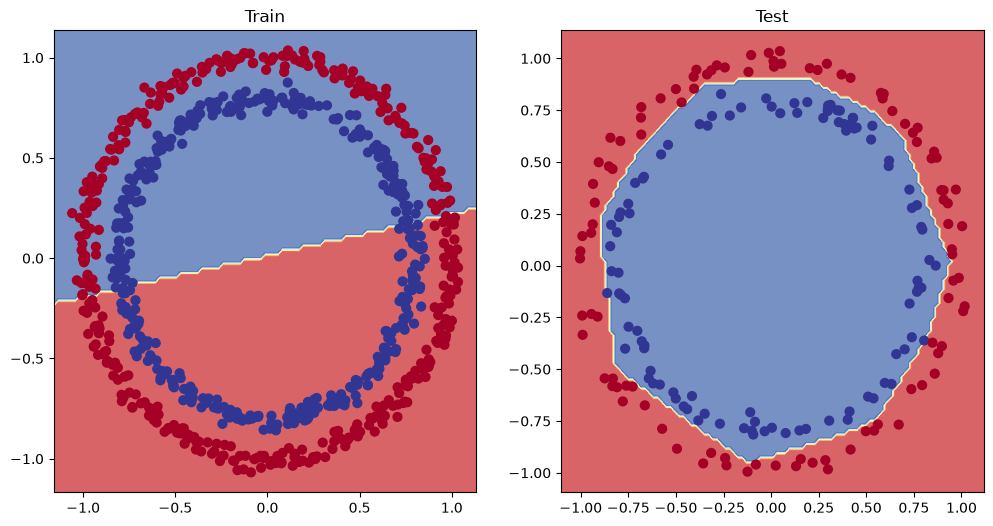

In [34]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_1,X_train,y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_3,X_test,y_test)

#### Replicating Non-Linear Activation Functions
what does a non-linear activation look like?
Replicating some activation functions and what they do.

In [35]:
a=torch.arange(-10,10,1,dtype=torch.float32)
a

tensor([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,   1.,
          2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.])

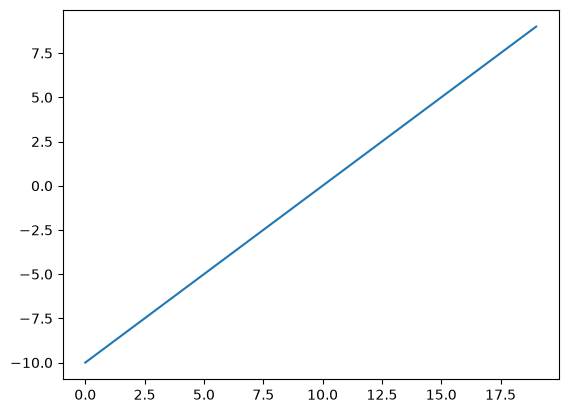

In [36]:
plt.plot(a)

let's see how a ReLU Activation Function influenes it. <br>
Let's write ReLU activation function ourself.<br>
ReLU function turns all negatives to 0 and leaves the positive values as they are


In [37]:
def relu(x):
    return torch.maximum(torch.tensor(0),x)
relu(a)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 2., 3., 4., 5., 6., 7.,
        8., 9.])

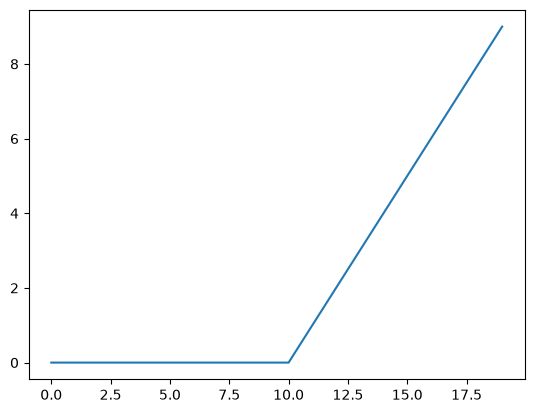

In [38]:
plt.plot(relu(a))

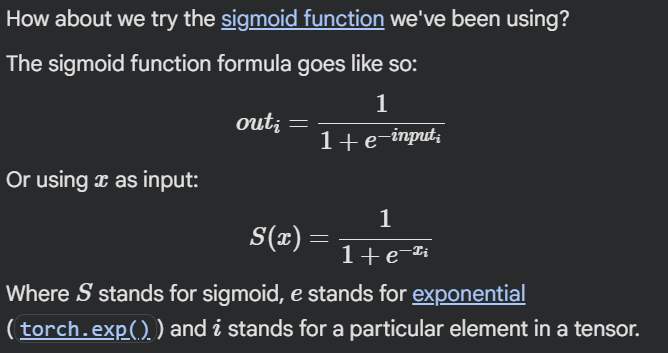

In [39]:
def sigmoid(x):
    return 1/(1+torch.exp(-x))
sigmoid(a)

tensor([4.5398e-05, 1.2339e-04, 3.3535e-04, 9.1105e-04, 2.4726e-03, 6.6929e-03,
        1.7986e-02, 4.7426e-02, 1.1920e-01, 2.6894e-01, 5.0000e-01, 7.3106e-01,
        8.8080e-01, 9.5257e-01, 9.8201e-01, 9.9331e-01, 9.9753e-01, 9.9909e-01,
        9.9966e-01, 9.9988e-01])

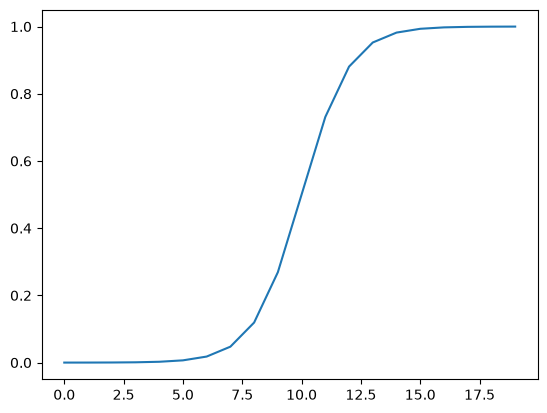

In [40]:
plt.plot(sigmoid(a))

### Putting everything together

![binary vs multi-class classification image with the example of dog vs cat for binary classification and dog vs cat vs chicken for multi-class classification](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/02-binary-vs-multi-class-classification.png)

### Creating multi-class classification data

To begin a multi-class classification problem, let's create some multi-class data.

To do so, we can leverage Scikit-Learn's [`make_blobs()`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html) method.

This method will create however many classes (using the `centers` parameter) we want.

Specifically, let's do the following:

1. Create some multi-class data with `make_blobs()`.
2. Turn the data into tensors (the default of `make_blobs()` is to use NumPy arrays).
3. Split the data into training and test sets using `train_test_split()`.
4. Visualize the data.

tensor([[-8.4134,  6.9352],
        [-5.7665, -6.4312],
        [-6.0421, -6.7661],
        [ 3.9508,  0.6984],
        [ 4.2505, -0.2815]]) tensor([3, 2, 2, 1, 1])


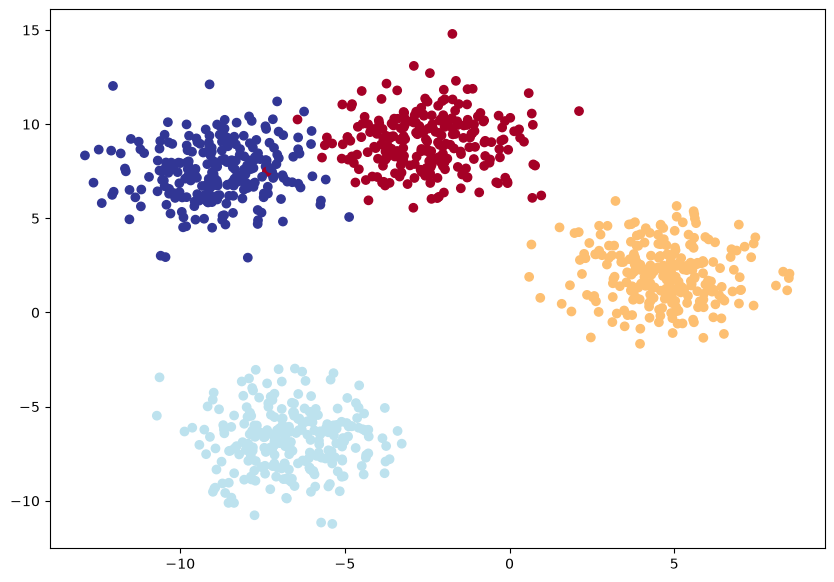

In [41]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

#data creation - set hyperparameters
NUM_CLASSES=4
NUM_FEATURES=2
RANDOM_SEED=42

X_blob,y_blob=make_blobs(n_samples=1000,
                         n_features=NUM_FEATURES, #x feautures
                         centers=NUM_CLASSES, #y labels
                         cluster_std=1.5, #give the clusters a lil shake up
                         random_state=RANDOM_SEED)

#turn data into tensors
X_blob=torch.from_numpy(X_blob).type(torch.float)
y_blob=torch.from_numpy(y_blob).type(torch.LongTensor)
print(X_blob[:5],y_blob[:5])

#split into train and test sets
X_blob_train,X_blob_test,y_blob_train,y_blob_test=train_test_split(X_blob,y_blob,test_size=0.2,random_state=RANDOM_SEED)

plt.figure(figsize=(10,7))
plt.scatter(X_blob[:,0],X_blob[:,1],c=y_blob,cmap=plt.cm.RdYlBu);

Does this dataset need nonlinearity? Or could you drwa a succession of straight lines to seperate it?

In [42]:
device="cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [43]:
from torch import nn

class BlobModel(nn.Module):
    def __init__(self,input_features,output_features,hidden_units=8):
        """Initializes all required hyperparameters for a multi-class classification model.

        Args:
            input_features (int): Number of input features to the model.
            out_features (int): Number of output features of the model
              (how many classes there are).
            hidden_units (int): Number of hidden units between layers, default 8.
        """
        super().__init__()
        self.linear_layer_stack=nn.Sequential(
            nn.Linear(in_features=input_features,out_features=hidden_units),
            nn.Linear(in_features=hidden_units,out_features=hidden_units),
            nn.Linear(in_features=hidden_units,out_features=output_features),
        )

    def forward(self,x):
        return self.linear_layer_stack(x)

model_4=BlobModel(input_features=NUM_FEATURES,output_features=NUM_CLASSES,hidden_units=8).to(device)
model_4,model_4.state_dict


(BlobModel(
   (linear_layer_stack): Sequential(
     (0): Linear(in_features=2, out_features=8, bias=True)
     (1): Linear(in_features=8, out_features=8, bias=True)
     (2): Linear(in_features=8, out_features=4, bias=True)
   )
 ),
 <bound method Module.state_dict of BlobModel(
   (linear_layer_stack): Sequential(
     (0): Linear(in_features=2, out_features=8, bias=True)
     (1): Linear(in_features=8, out_features=8, bias=True)
     (2): Linear(in_features=8, out_features=4, bias=True)
   )
 )>)

In [44]:
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(params=model_4.parameters(),lr=0.1)

In [45]:
#lets try a single forward class
model_4(X_blob_train.to(device))[:5]

tensor([[-1.2711, -0.6494, -1.4740, -0.7044],
        [ 0.2210, -1.5439,  0.0420,  1.1531],
        [ 2.8698,  0.9143,  3.3169,  1.4027],
        [ 1.9576,  0.3125,  2.2244,  1.1324],
        [ 0.5458, -1.2381,  0.4441,  1.1804]], grad_fn=<SliceBackward0>)

In [46]:
model_4(X_blob_train.to(device))[0].shape,NUM_CLASSES

(torch.Size([4]), 4)

In [47]:
y_logits=model_4(X_blob_test.to(device))

y_pred_probs=torch.softmax(y_logits,dim=1)
y_logits[:5],y_pred_probs[:5]

(tensor([[-1.2549, -0.8112, -1.4795, -0.5696],
         [ 1.7168, -1.2270,  1.7367,  2.1010],
         [ 2.2400,  0.7714,  2.6020,  1.0107],
         [-0.7993, -0.3723, -0.9138, -0.5388],
         [-0.4332, -1.6117, -0.6891,  0.6852]], grad_fn=<SliceBackward0>),
 tensor([[0.1872, 0.2918, 0.1495, 0.3715],
         [0.2824, 0.0149, 0.2881, 0.4147],
         [0.3380, 0.0778, 0.4854, 0.0989],
         [0.2118, 0.3246, 0.1889, 0.2748],
         [0.1945, 0.0598, 0.1506, 0.5951]], grad_fn=<SliceBackward0>))

In [48]:
torch.sum(y_pred_probs[0]),torch.argmax(y_pred_probs[2])

(tensor(1.0000, grad_fn=<SumBackward0>), tensor(2))

This is just random guessing, as we haven't trained out model yet.

### Training Loops for a Multi Class PyTorch Model

In [49]:
torch.manual_seed(42)

epochs=100
X_blob_train,X_blob_test=X_blob_train.to(device),X_blob_test.to(device)
y_blob_train,y_blob_test=y_blob_train.to(device),y_blob_test.to(device)

for epoch in range(epochs):
    model_4.train()
    y_logits=model_4(X_blob_train)
    y_pred=torch.softmax(y_logits,dim=1).argmax(dim=1)

    loss=loss_fn(y_logits,y_blob_train)
    acc=accuracy_fn(y_true=y_blob_train,y_pred=y_pred)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model_4.eval()
    with torch.inference_mode():
        test_logits=model_4(X_blob_test)
        test_pred=torch.softmax(test_logits,dim=1).argmax(dim=1)
        test_loss=loss_fn(test_logits,y_blob_test)
        test_acc=accuracy_fn(y_true=y_blob_test,y_pred=test_pred)

    if epoch%10==0:
         print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%") 

Epoch: 0 | Loss: 1.04324, Acc: 65.50% | Test Loss: 0.57861, Test Acc: 95.50%
Epoch: 10 | Loss: 0.14398, Acc: 99.12% | Test Loss: 0.13037, Test Acc: 99.00%
Epoch: 20 | Loss: 0.08062, Acc: 99.12% | Test Loss: 0.07216, Test Acc: 99.50%
Epoch: 30 | Loss: 0.05924, Acc: 99.12% | Test Loss: 0.05133, Test Acc: 99.50%
Epoch: 40 | Loss: 0.04892, Acc: 99.00% | Test Loss: 0.04098, Test Acc: 99.50%
Epoch: 50 | Loss: 0.04295, Acc: 99.00% | Test Loss: 0.03486, Test Acc: 99.50%
Epoch: 60 | Loss: 0.03910, Acc: 99.00% | Test Loss: 0.03083, Test Acc: 99.50%
Epoch: 70 | Loss: 0.03643, Acc: 99.00% | Test Loss: 0.02799, Test Acc: 99.50%
Epoch: 80 | Loss: 0.03448, Acc: 99.00% | Test Loss: 0.02587, Test Acc: 99.50%
Epoch: 90 | Loss: 0.03300, Acc: 99.12% | Test Loss: 0.02423, Test Acc: 99.50%


In [50]:
model_4.eval()
with torch.inference_mode():
    y_logits=model_4(X_blob_test)
    y_pred_probs=torch.softmax(y_logits,dim=1)
    y_preds=y_pred_probs.argmax(dim=1)
print(f"pred:{y_preds[:10]},\ny_true:{y_blob_test[:10]},\nacc:{accuracy_fn(y_true=y_blob_test,y_pred=y_preds)}%")
      

pred:tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0]),
y_true:tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0]),
acc:99.5%


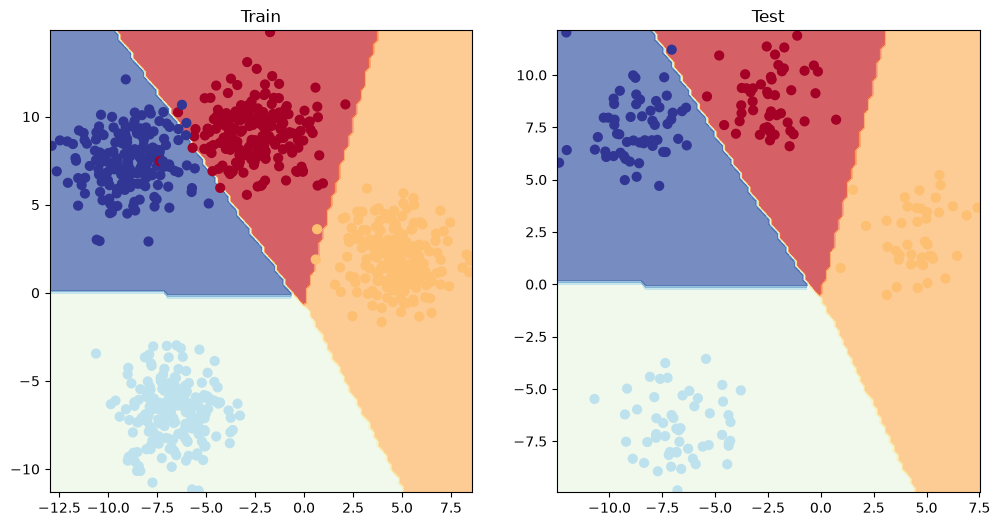

In [51]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_4,X_blob_train,y_blob_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_4,X_blob_test,y_blob_test)

#### More Evaluation Metrics
| **Metric name/Evaluation method** | **Defintion** | **Code** |
| --- | --- | --- |
| Accuracy | Out of 100 predictions, how many does your model get correct? E.g. 95% accuracy means it gets 95/100 predictions correct. | [`torchmetrics.Accuracy()`](https://torchmetrics.readthedocs.io/en/stable/classification/accuracy.html#id3) or [`sklearn.metrics.accuracy_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) |
| Precision | Proportion of true positives over total number of samples. Higher precision leads to less false positives (model predicts 1 when it should've been 0). | [`torchmetrics.Precision()`](https://torchmetrics.readthedocs.io/en/stable/classification/precision.html#id4) or [`sklearn.metrics.precision_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html) |
| Recall | Proportion of true positives over total number of true positives and false negatives (model predicts 0 when it should've been 1). Higher recall leads to less false negatives. | [`torchmetrics.Recall()`](https://torchmetrics.readthedocs.io/en/stable/classification/recall.html#id5) or [`sklearn.metrics.recall_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html) |
| F1-score | Combines precision and recall into one metric. 1 is best, 0 is worst. | [`torchmetrics.F1Score()`](https://torchmetrics.readthedocs.io/en/stable/classification/f1_score.html#f1score) or [`sklearn.metrics.f1_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html) |
| [Confusion matrix](https://www.dataschool.io/simple-guide-to-confusion-matrix-terminology/)  | Compares the predicted values with the true values in a tabular way, if 100% correct, all values in the matrix will be top left to bottom right (diagnol line). | [`torchmetrics.ConfusionMatrix`](https://torchmetrics.readthedocs.io/en/stable/classification/confusion_matrix.html#confusionmatrix) or [`sklearn.metrics.plot_confusion_matrix()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay.from_predictions) |
| Classification report | Collection of some of the main classification metrics such as precision, recall and f1-score. | [`sklearn.metrics.classification_report()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html) |

In [52]:
from torchmetrics import Accuracy
torchmetrics_Accuracy=Accuracy(task='multiclass',num_classes=4).to(device)
torchmetrics_Accuracy(y_preds,y_blob_test)

ModuleNotFoundError: No module named 'pkg_resources'